### Research Question 6: Neighborhood analysis

#### Are the model's predictions locally consistent among visually similar X-ray images, and does this consistency differ between correctly and incorrectly classified samples?

We investigate whether correctly and incorrectly classified X-ray images differ in the composition of their nearest-neighbor neighborhoods.

In particular, we examine the consistency of model predictions among the nearest neighbors of true positives (TP), false positives (FP), true negatives (TN), and false negatives (FN).

We analyze whether neighboring images receive similar model predictions and whether misclassifications occur in regions characterized by consistent or inconsistent predictions.

Additionally, we compare these neighborhood characteristics across different feature representations (raw pixels, PCA, and UMAP).

In [1]:
from IPython.utils.capture import capture_output
import ipywidgets as widgets
from IPython.display import display, clear_output

with capture_output() as captured:
    %run neighbor_analysis.ipynb

In [2]:
images = np.stack([x["img"] for x in XRAY_DATASET])

In [3]:
def create_comparison_widget():    
    pathology_dropdown = widgets.Dropdown(
        options=list(DATASET_LABEL_INDICES_MAP.keys()),
        description="Pathology:",
        style={"description_width": "100px"},
        layout=widgets.Layout(width="350px"))

    classification_dropdown = widgets.Dropdown(
        options=["FP", "TP", "FN", "TN"],
        value="FP",
        description="Classification:",
        style={"description_width": "100px"},
        layout=widgets.Layout(width="250px"))

    threshold_slider = widgets.FloatSlider(
        value=0.5,
        min=0.0,
        max=1.0,
        step=0.05,
        description="Threshold:",
        readout_format=".2f",
        style={"description_width": "100px"},
        layout=widgets.Layout(width="350px"))

    create_button = widgets.Button(
        description="Create comparison",
        button_style="primary",
        icon="refresh")

    output = widgets.Output()

    def create_comparison(_):
        with output:
            clear_output(wait=True)

            pathology = pathology_dropdown.value
            classification = classification_dropdown.value
            threshold = threshold_slider.value

            # Dataset and model indices
            dataset_idx = DATASET_LABEL_INDICES_MAP[pathology]

            ground_truth = XRAY_LABELS_LIST[:, dataset_idx]
            predictions = MODEL_SCORE_PREDICTIONS_CONVERTED[:, dataset_idx]

            # Ignore samples without valid ground truth
            valid = np.isin(ground_truth, [0, 1]) & np.isfinite(predictions)
            positive = predictions >= threshold

            masks = {
                "TP": valid & (ground_truth == 1) & positive,
                "FP": valid & (ground_truth == 0) & positive,
                "TN": valid & (ground_truth == 0) & ~positive,
                "FN": valid & (ground_truth == 1) & ~positive}

            error_idx = np.flatnonzero(masks[classification])

            if len(error_idx) == 0:
                print(f"No {classification} images found for {pathology}.")
                return

            print(f"{pathology} | {classification} with treshold {threshold:.2f}| {len(error_idx)} candidates")

            # Calculate neighbors and projections
            query_idx, neighbors, feature_space = query_error_with_downprojection(
                images=images,
                error_idx=error_idx)

            # Plot 1: Nearest-neighbor image comparison
            plot_neighbor_comparison(
                query_idx=query_idx,
                neighbors=neighbors,
                images=images,
                ground_truth=ground_truth,
                predictions=predictions,
                threshold=threshold)

            # Plot 1.2: Visualize Overlap
            visualize_overlap(neighbors=neighbors)

            # Class distribution for selected pathology
            print(f"\nClass distribution for {pathology}:")
            print(f"Positive: {np.mean(ground_truth[valid] == 1):.2%}")
            print(f"Negative: {np.mean(ground_truth[valid] == 0):.2%}")

    create_button.on_click(create_comparison)

    widget = widgets.VBox([
        pathology_dropdown,
        classification_dropdown,
        threshold_slider,
        create_button,
        output
    ])
    return widget

In [4]:
display(create_comparison_widget())

We compare neighborhood prediction agreements for a each pathology with different numbers of neighbors k.

In [5]:
def calculate_feature_space(images):
    # Flatten images for pixel-based comparison
    X_raw = images.reshape(len(images), -1).astype(np.float32)

    # PCA
    pca = PCA(n_components=100)
    X_pca = pca.fit_transform(X_raw)       

    # UMAP (with PCA features)
    X_umap = umap.UMAP(n_components=2,
                              n_neighbors=10,
                              min_dist=0.1,
                              random_state=42).fit_transform(X_pca)

    # NN
    feature_space = {"Raw": X_raw,
                     "PCA": X_pca,
                     "UMAP": X_umap}
    return feature_space

In [6]:
feature_space = calculate_feature_space(images)

Neighborhood prediction agreement for Atelectasis
Processing Raw...
Processing PCA...
Processing UMAP...
Predicted positive: 53.10%
Predicted negative: 46.90%


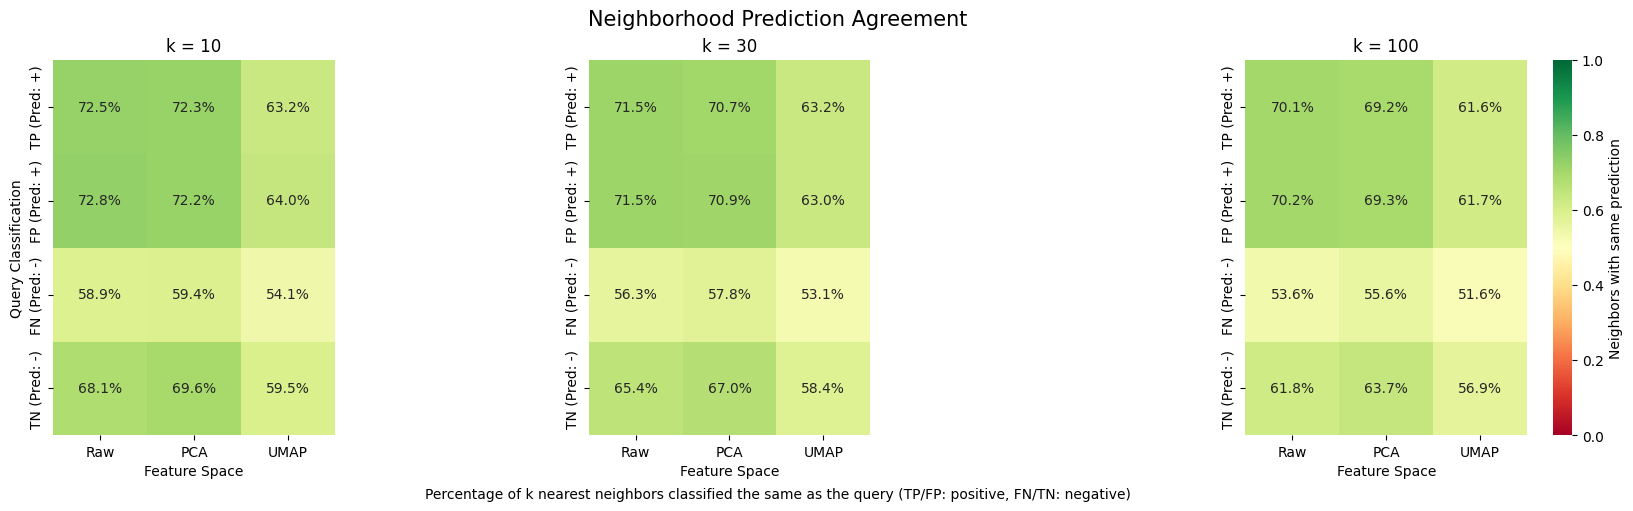

Neighborhood prediction agreement for Cardiomegaly
Processing Raw...
Processing PCA...
Processing UMAP...
Predicted positive: 38.05%
Predicted negative: 61.95%


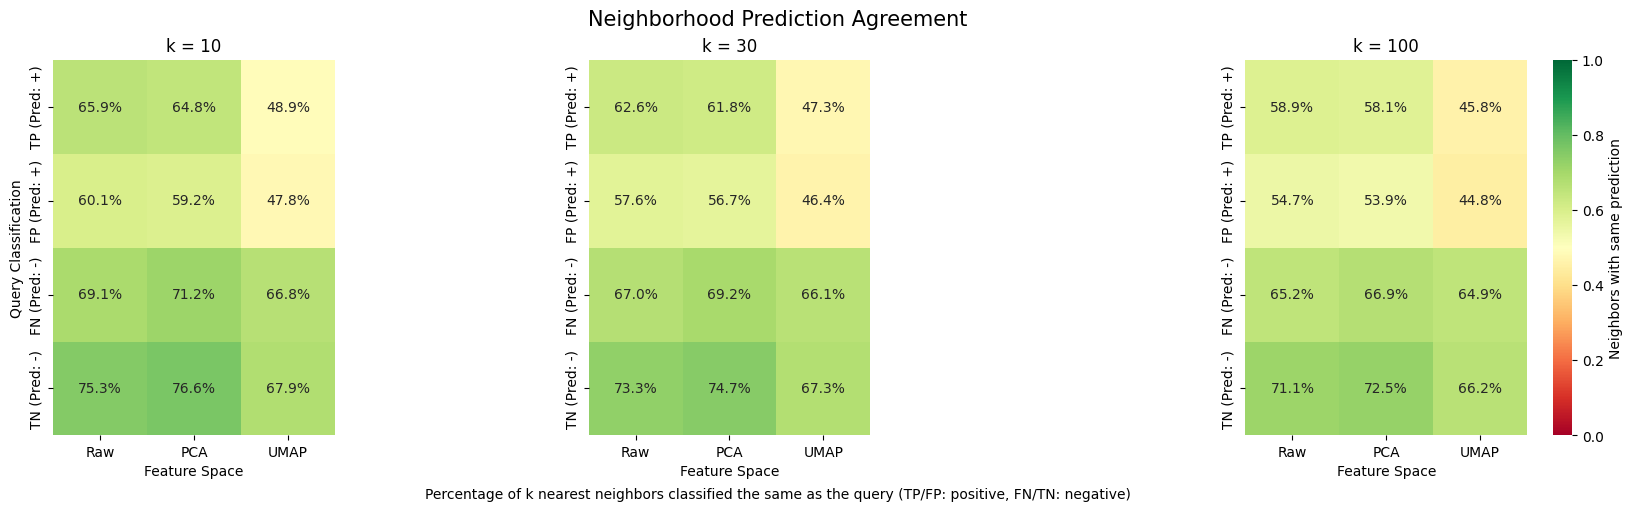

Neighborhood prediction agreement for Consolidation
Processing Raw...
Processing PCA...
Processing UMAP...
Predicted positive: 28.21%
Predicted negative: 71.79%


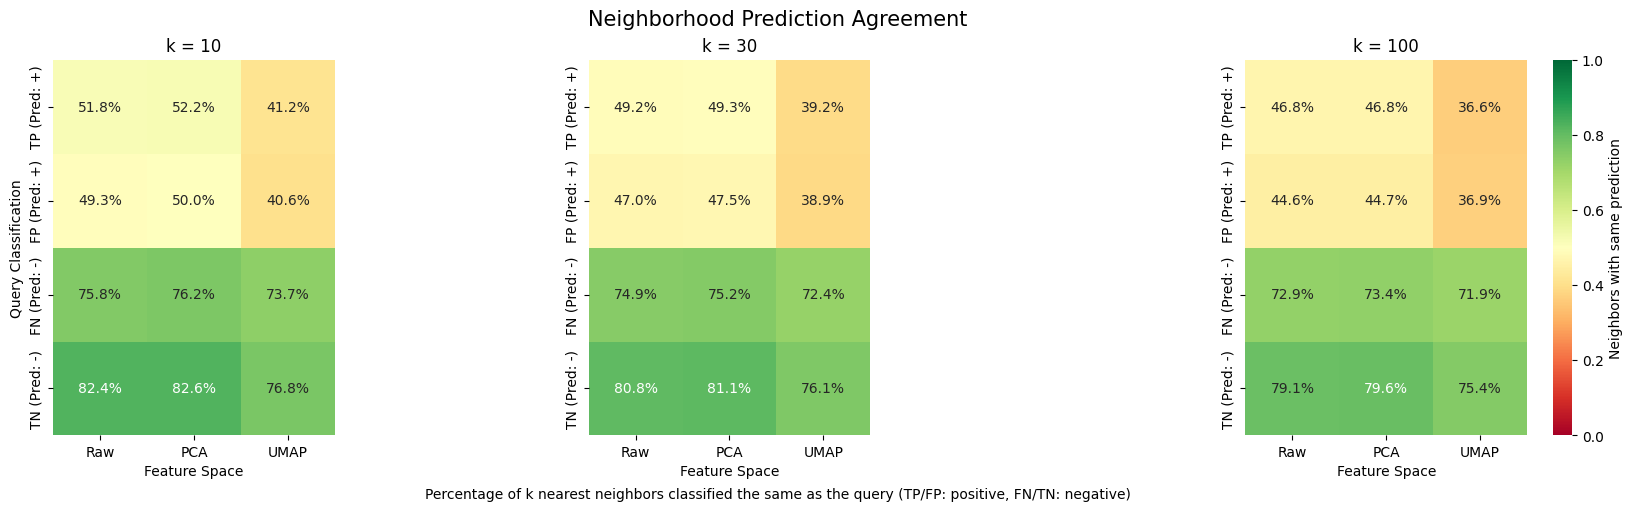

Neighborhood prediction agreement for Edema
Processing Raw...
Processing PCA...
Processing UMAP...
Predicted positive: 41.91%
Predicted negative: 58.09%


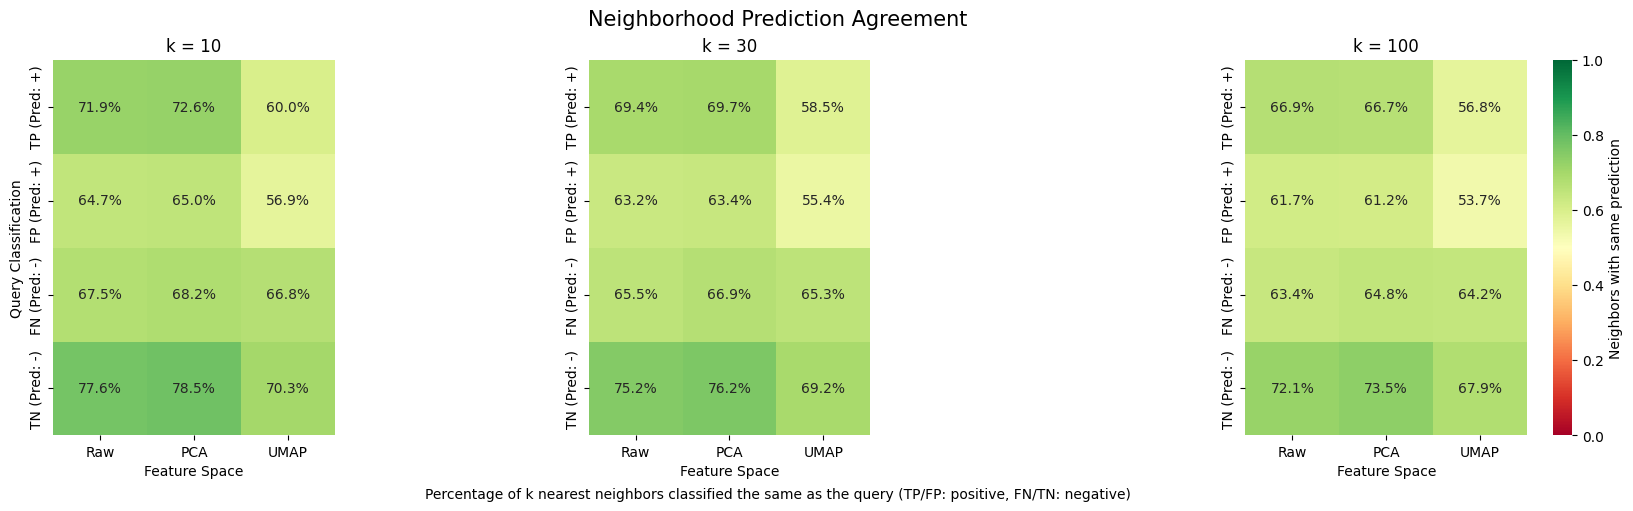

Neighborhood prediction agreement for Enlarged Cardiomediastinum
Processing Raw...
Processing PCA...
Processing UMAP...
Predicted positive: 20.96%
Predicted negative: 79.04%


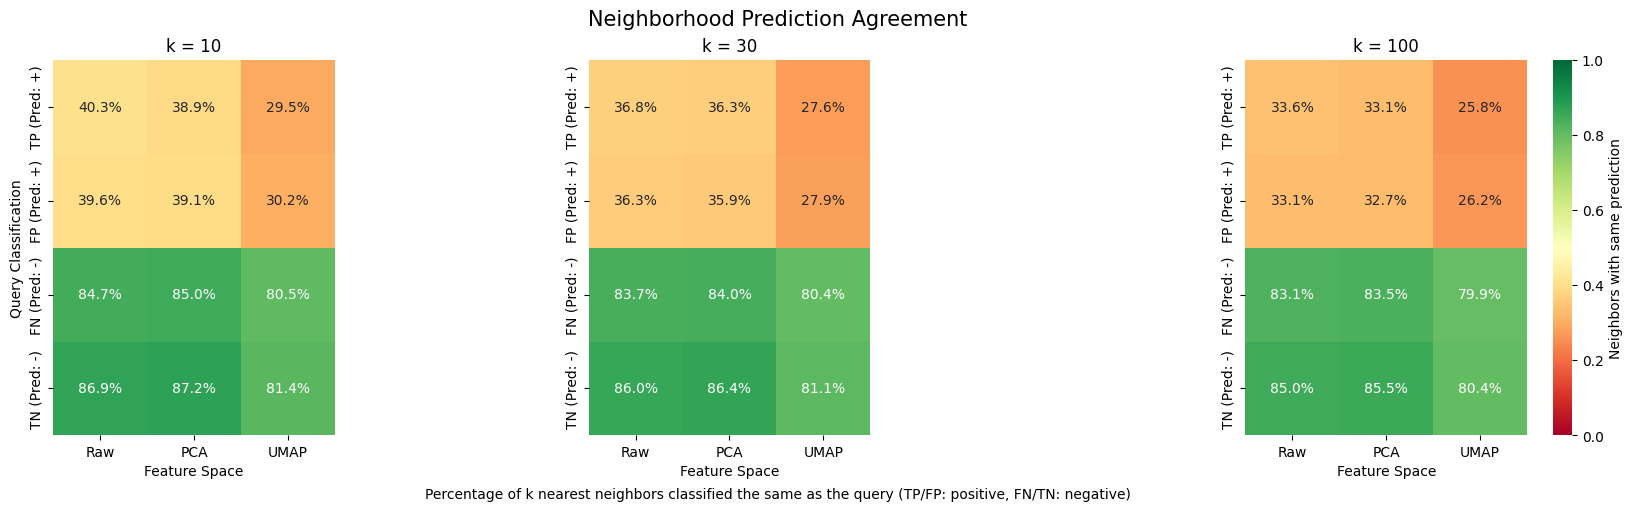

Neighborhood prediction agreement for Fracture
Processing Raw...
Processing PCA...
Processing UMAP...
Predicted positive: 11.25%
Predicted negative: 88.75%


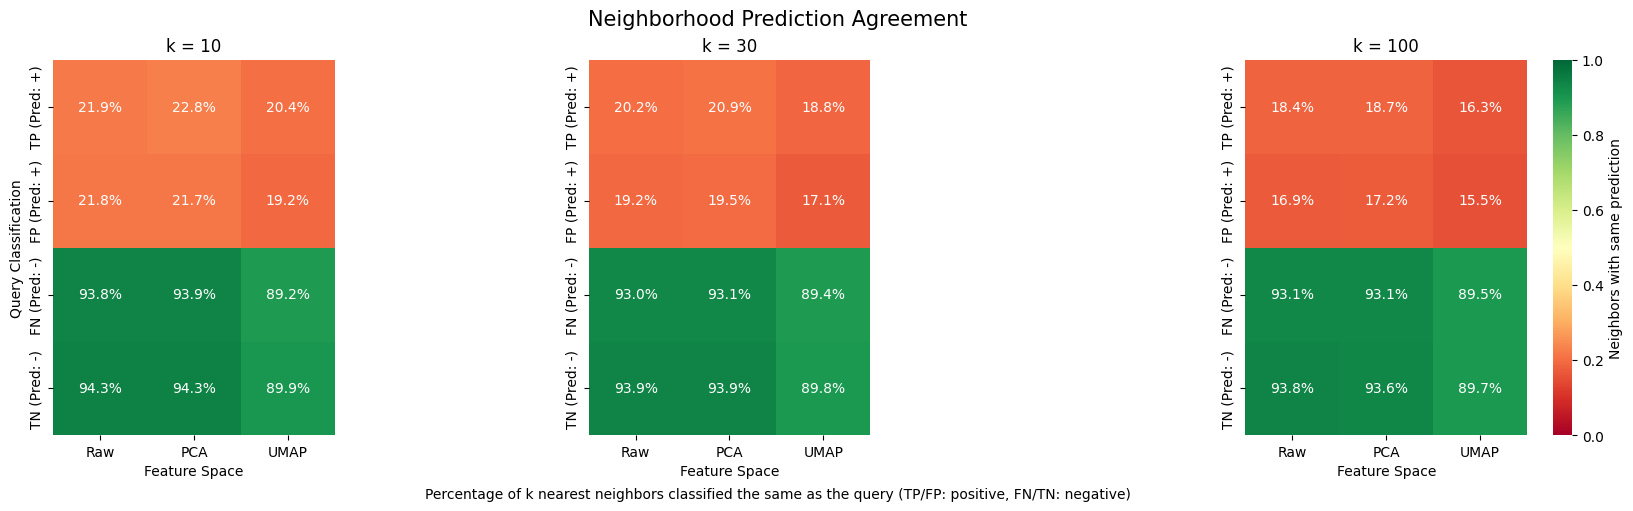

Neighborhood prediction agreement for Lung Lesion
Processing Raw...
Processing PCA...
Processing UMAP...
Predicted positive: 14.04%
Predicted negative: 85.96%


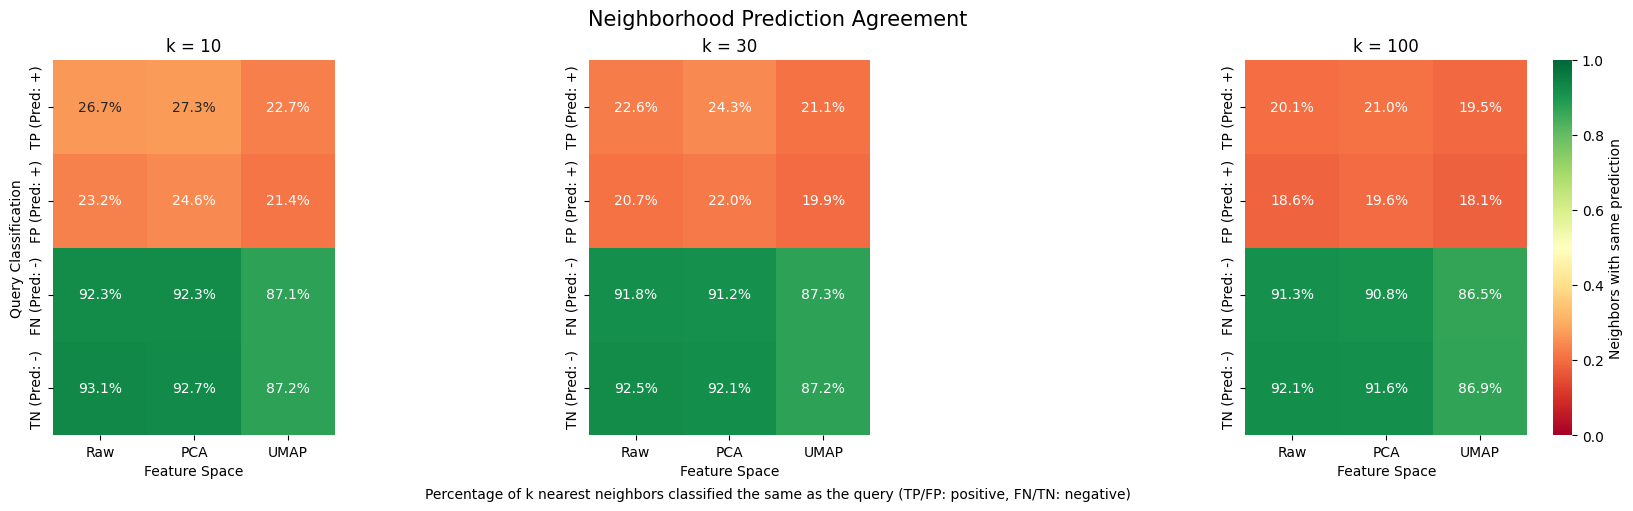

Neighborhood prediction agreement for Lung Opacity
Processing Raw...
Processing PCA...
Processing UMAP...
Predicted positive: 56.86%
Predicted negative: 43.14%


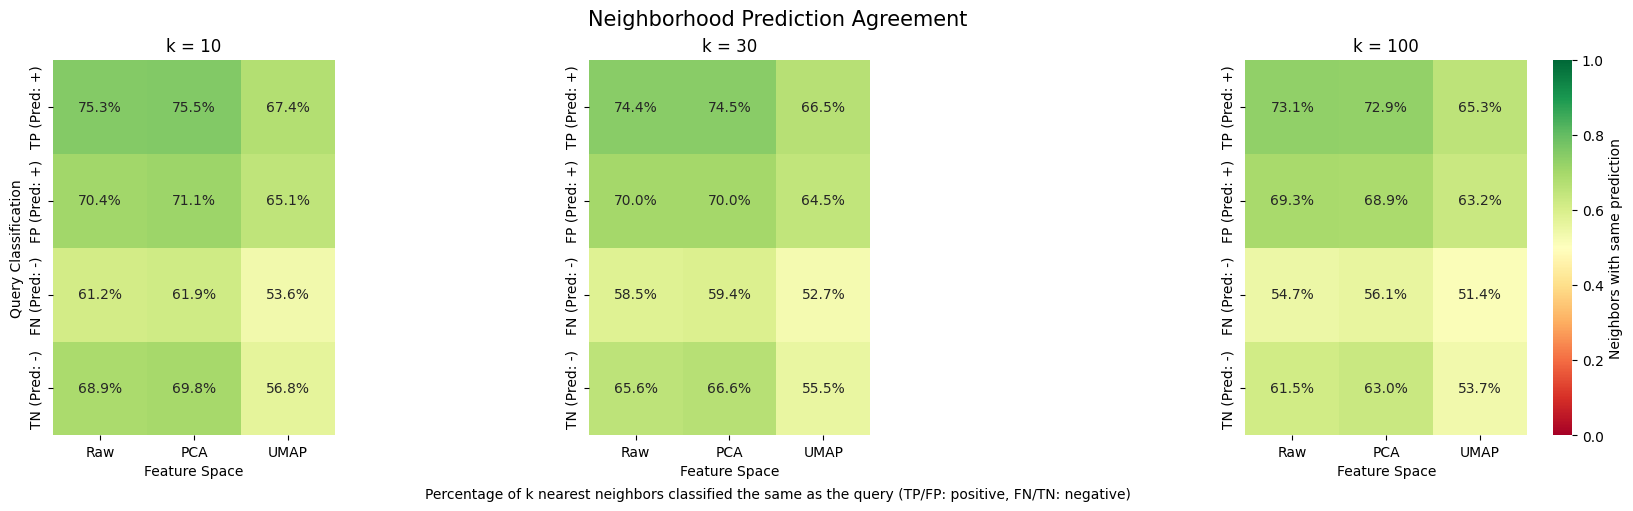

Neighborhood prediction agreement for Effusion
Processing Raw...
Processing PCA...
Processing UMAP...
Predicted positive: 46.24%
Predicted negative: 53.76%


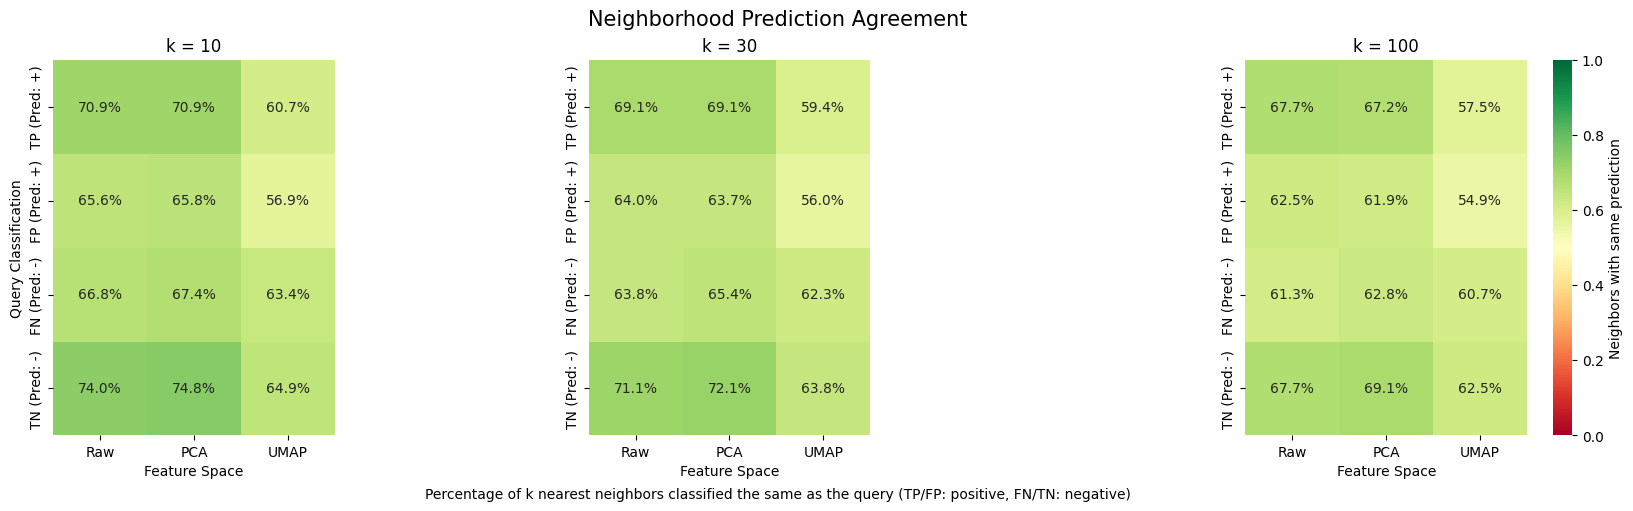

Neighborhood prediction agreement for Pneumonia
Processing Raw...
Processing PCA...
Processing UMAP...
Predicted positive: 15.11%
Predicted negative: 84.89%


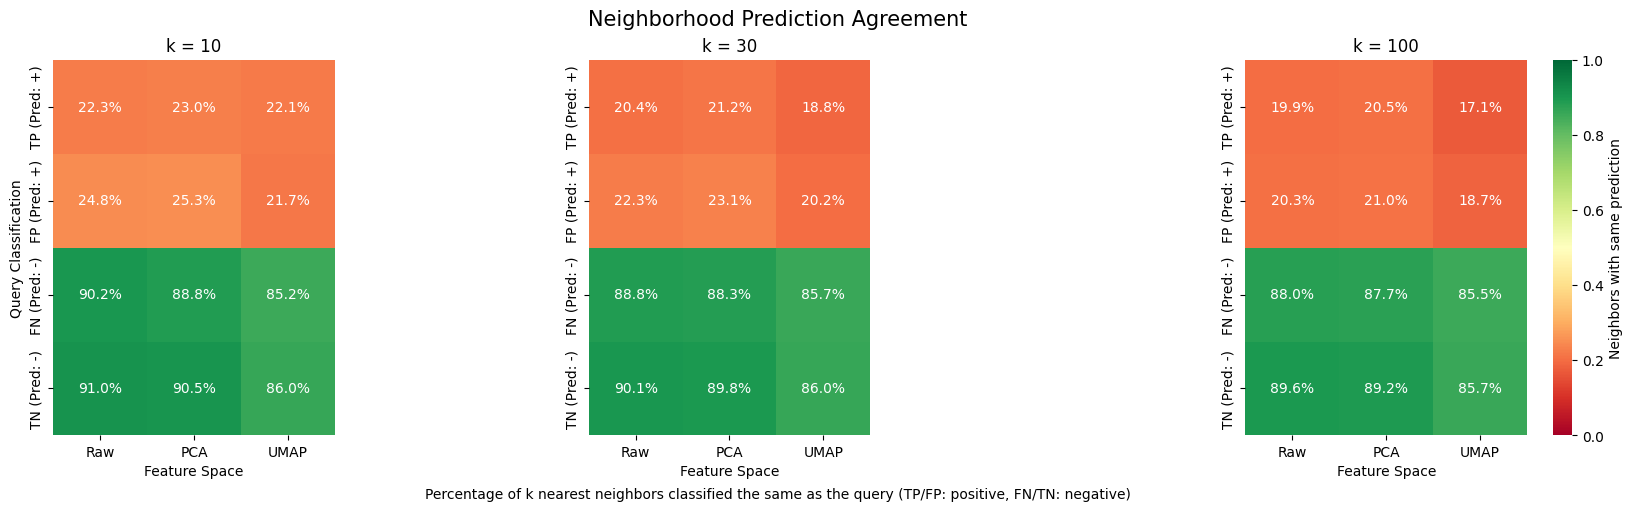

Neighborhood prediction agreement for Pneumothorax
Processing Raw...
Processing PCA...
Processing UMAP...
Predicted positive: 0.34%
Predicted negative: 99.66%


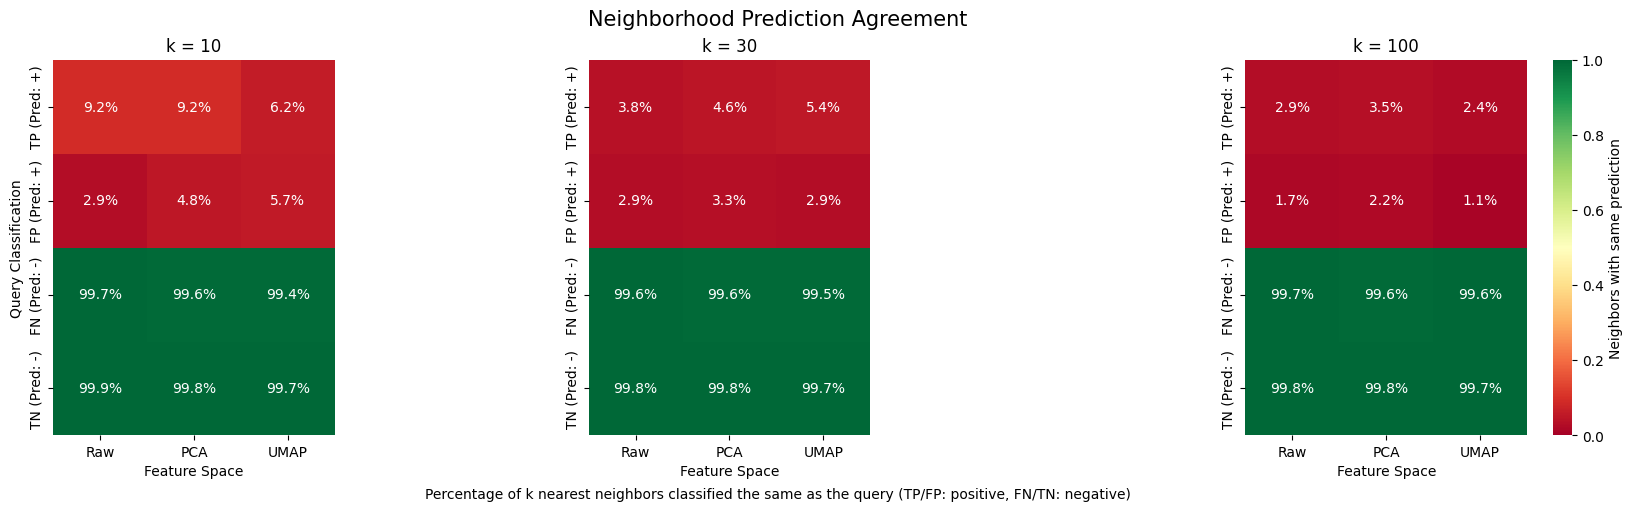

In [7]:
for pathology in XRAY_DATASET.pathologies:

    print(f"Neighborhood prediction agreement for {pathology}")
    dataset_idx = DATASET_LABEL_INDICES_MAP[pathology]
    ground_truth = XRAY_LABELS_LIST[:, dataset_idx]
    predictions = MODEL_SCORE_PREDICTIONS_CONVERTED[:, dataset_idx]
    
    agreement_results = calculate_agreement_heatmap(
        feature_space=feature_space,
        ground_truth=ground_truth,
        predictions=predictions,
        threshold=0.7,
        k_values=[10, 30, 100])

    plot_agreement_heatmaps(agreement_results)

# Findings
Neighborhood prediction consistency highly varies across diseases. For Pneumothorax, Fracture and Lung Lesion, neighborhoods are dominated by negative predictions, whereas Edma und Cardiomegaly show more balanced prediction patterns.

Negative predictions seem to dominate for several pathologies. Even correctly identified positive cases are frequently surrounded by negatives - this is especially present for Pneumothorax.
Correctly classified samples only show a slightly higher neighborhood prediction agreement than incorrectly classified samples (e.g. present for Edema and Cardiomegaly)

Raw pixels and PCA produce largely similar agreement patterns in contrast to UMAP. This could explained by the high number of features used for PCA (100 instead of only 2).

Agreement seem to decrease as k increases, suggesting that predictions are somewhat more consistent among closer neighbors.